# Figure 3

![Full Figure](../figures/fig03_FULL.png)

## Code for Figure 3: violation history

**Goal:** Reproduce the violation-history GLM panels with the submitted plot styling; Panel A uses the corrected autocorrelation statistics from the revision.

| Panel | Content |
|---|---|
| A | Session-level violation autocorrelogram (±20 lags) |
| B | Binary previous-violation intuition and GLM weights |
| C | Filtered previous-violation intuition and GLM weights |
| D | Exponential time-constant sweep (heatmap) |
| E | Example animal τ profile |
| F | History-model comparison |

**Outputs:** `figures/fig03a_violation_autocorrelation.png`, `figures/fig03b_prev_violation_intuition.png`, `figures/fig03b_prev_violation_weights.png`, `figures/fig03c_filtered_intuition.png`, `figures/fig03c_filtered_weights.png`, `figures/fig03d_tau_heatmap.png`, `figures/fig03e_example_tau.png`, `figures/fig03f_model_comparison.png`.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import seaborn as sns

from violations_glm.config import (
    MODEL_COMPARE_COLOR,
    MULTI_CHOICE_PALETTE,
    PREV_VIOLATION_COLOR,
    PREV_VIOLATION_FILTER_COLOR,
    VIOLATION_COLOR,
)
from violations_glm.features import exponential_kernel
from violations_glm.io import load_autocorrelation_summary, load_model_summary
from violations_glm.plotting import configure_publication_dpi, save_figure
from violations_glm.summaries import (
    best_fits,
    bits_per_trial,
    geometric_mean_likelihood_ratio,
    overall_likelihood_ratio,
    unpack_weights,
)

configure_publication_dpi()
sns.set_context("talk")

In [2]:
RAW_FIT = "2025_07_19_fig3_fit_prev_violation_rs47"
FILTERED_FIT = "2025_07_19_fig3_fit_filt_prev_violation_rs47"
TAU_SWEEP = "2025_07_19_fig3_sweep_prev_viol_taus_rs47"
COMPARE = "2025_07_19_fig3_compare_prev_viol_rs47"
WEIGHT_YMIN, WEIGHT_YMAX = -2.1, 2.1
EXAMPLE_ANIMAL = "W075"

INTUITION = pd.DataFrame(
    {
        "trial": np.arange(1, 11),
        "violation": [0, 1, 0, 0, 0, 0, 1, 0, 0, 0],
        "prev_violation": [0, 0, 1, 0, 0, 0, 0, 1, 0, 0],
    }
)

## Panel A — Violation autocorrelation

Statistics are produced by [`scripts/compute_fig03_autocorrelation.py`](../scripts/compute_fig03_autocorrelation.py) (not run in this notebook). Relative to the submitted notebook: **10,000** within-session permutations (was 100), empirical p-values `(count + 1) / (n + 1)`, Bonferroni over **lags 1–20 only** (negative lags mirror positive), one reusable null array, random seed **47**; 1,000 session bootstrap resamples and ±20-lag plotting are unchanged. Edge-trimmed robustness is [Supporting Figure S6 panel D](suppS6.ipynb) via the same script with `--edge-trials 10`.

/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_2289/4190600304.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  significant = autocorrelation["significant"].fillna(False).astype(bool)


Bonferroni-significant positive lags: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 19]
Lag-1 observed mean: 0.11708833019806736


/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_2289/4190600304.py:72: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sig_lags = positive.loc[positive["significant"].fillna(


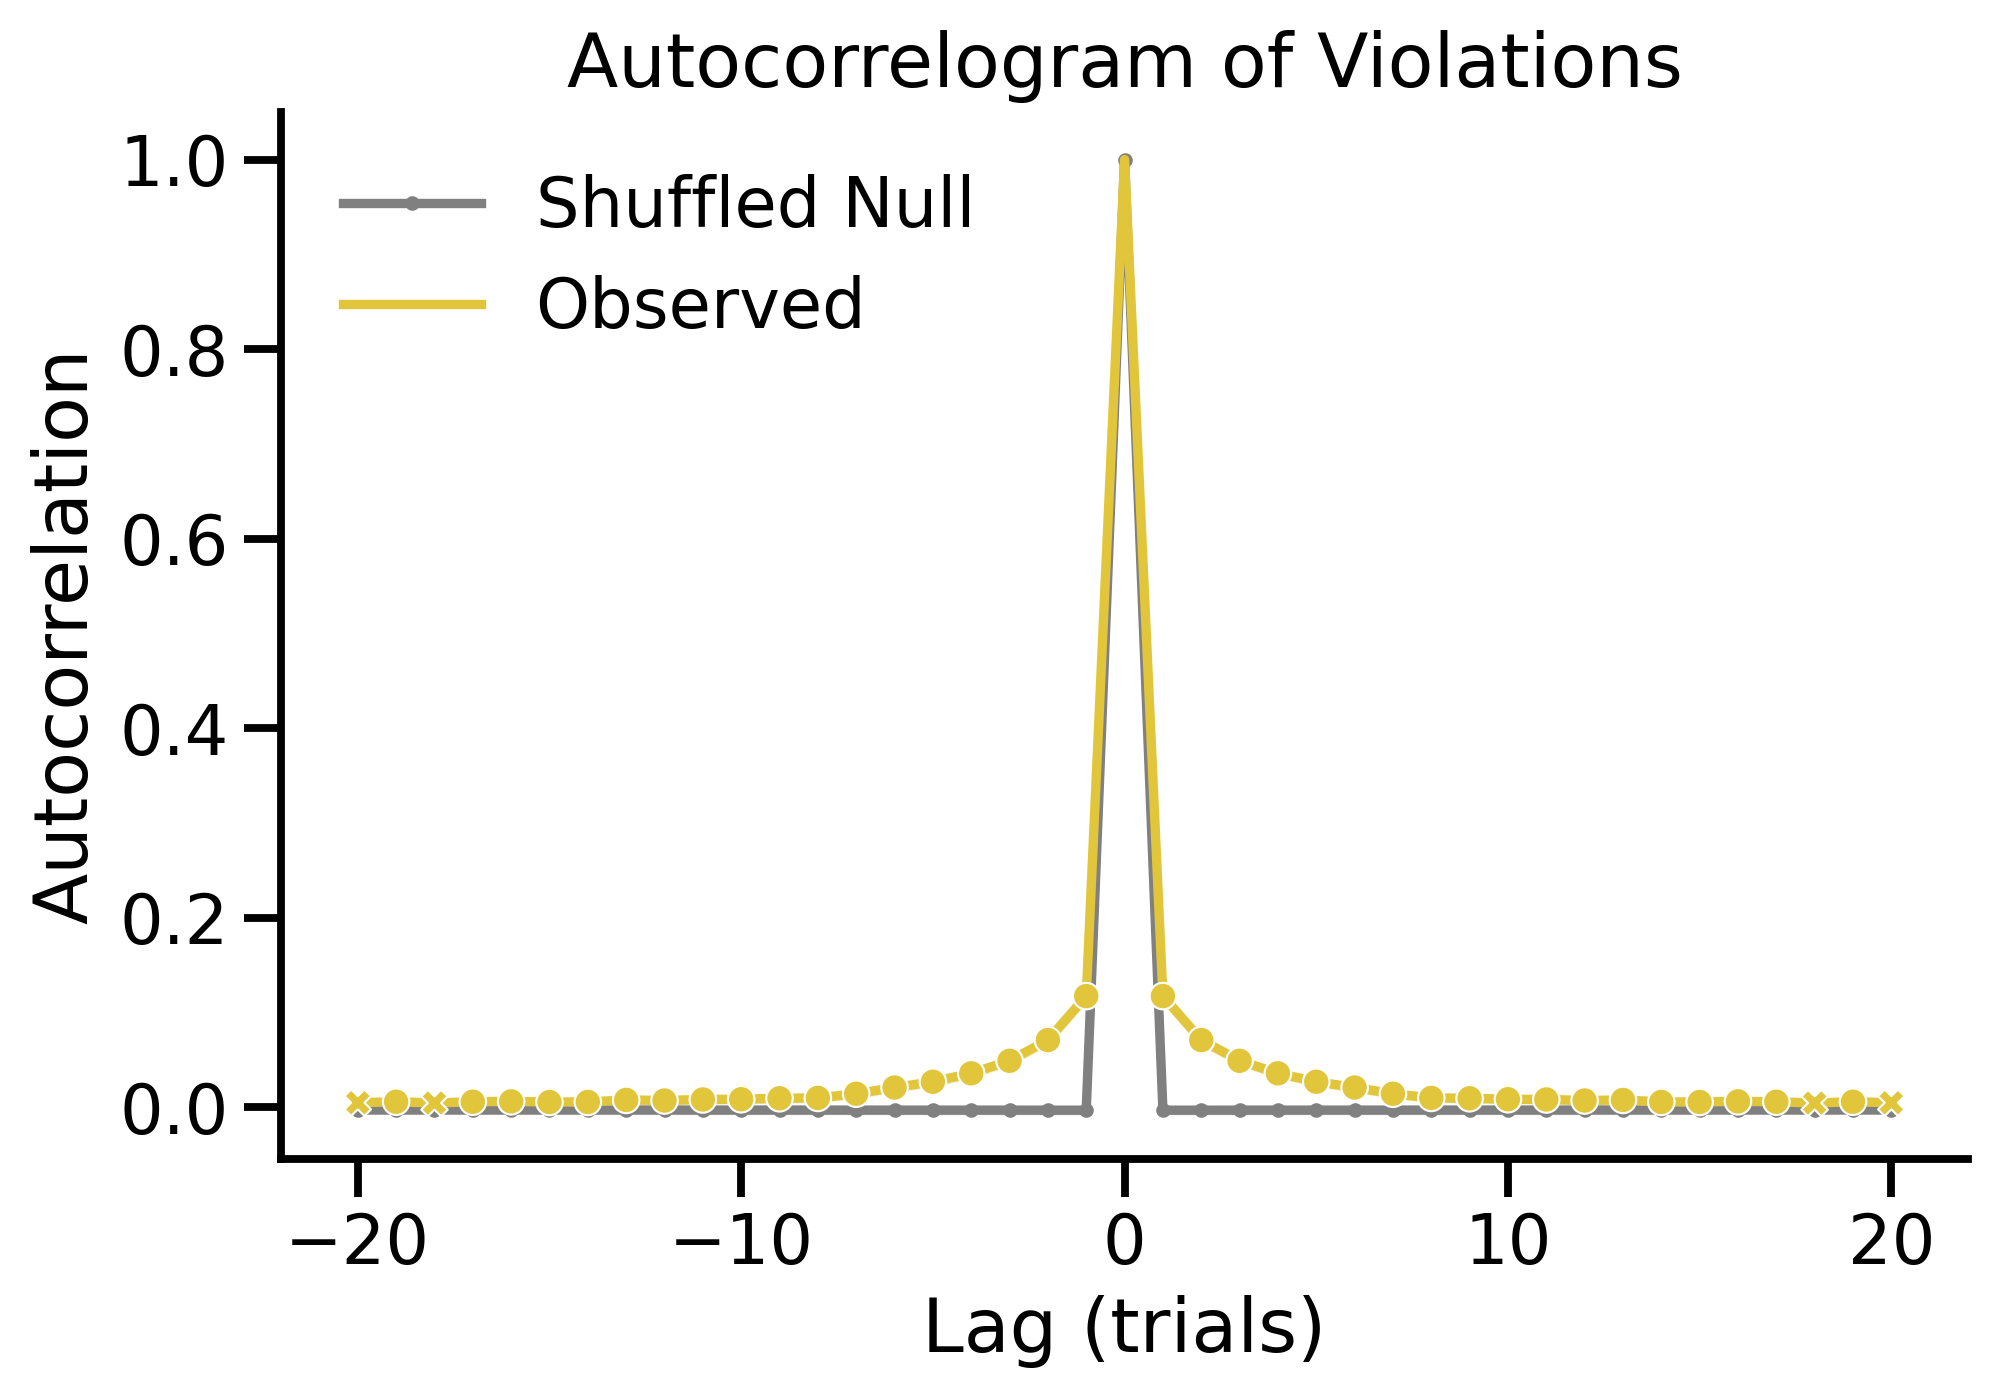

In [3]:
autocorrelation = load_autocorrelation_summary()
lags = autocorrelation["lag"]
significant = autocorrelation["significant"].fillna(False).astype(bool)
df_obs = pd.DataFrame(
    {
        "lags": lags,
        "obs_mean_ac": autocorrelation["observed_mean"],
        "Significance": np.where(significant, "Significant", "Non-significant"),
    }
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    lags,
    autocorrelation["null_mean"],
    label="Shuffled Null",
    color="gray",
    marker=".",
    markersize=5,
)
ax.fill_between(
    lags,
    autocorrelation["null_ci_lower"],
    autocorrelation["null_ci_upper"],
    alpha=0.3,
    color="gray",
)
sns.lineplot(
    data=df_obs,
    x="lags",
    y="obs_mean_ac",
    ax=ax,
    color=VIOLATION_COLOR,
    linestyle="-",
    label="Observed",
)
marker_df = df_obs.loc[df_obs["lags"] != 0]
sns.scatterplot(
    data=marker_df,
    x="lags",
    y="obs_mean_ac",
    hue="Significance",
    palette={
        "Significant": VIOLATION_COLOR,
        "Non-significant": VIOLATION_COLOR,
    },
    style="Significance",
    markers={"Significant": "o", "Non-significant": "X"},
    legend=False,
    ax=ax,
    zorder=10,
    size=20,
)
ax.fill_between(
    lags,
    autocorrelation["observed_ci_lower"],
    autocorrelation["observed_ci_upper"],
    alpha=0.3,
    color=VIOLATION_COLOR,
)
ax.set(
    title="Autocorrelogram of Violations",
    xlabel="Lag (trials)",
    ylabel="Autocorrelation",
)
ax.legend(frameon=False, loc="upper left")
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "fig03a_violation_autocorrelation")

positive = autocorrelation.loc[(autocorrelation["lag"] > 0)]
sig_lags = positive.loc[positive["significant"].fillna(
    False), "lag"].astype(int).tolist()
print("Bonferroni-significant positive lags:", sig_lags)
print(
    "Lag-1 observed mean:",
    float(positive.loc[positive["lag"] == 1, "observed_mean"].iloc[0]),
)

## Panel B — Previous violation intuition and weights

GLM fits are from [`scripts/fit_fig03.py`](../scripts/fit_fig03.py); this notebook loads stable summaries only.

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig03b_prev_violation_weights.png')

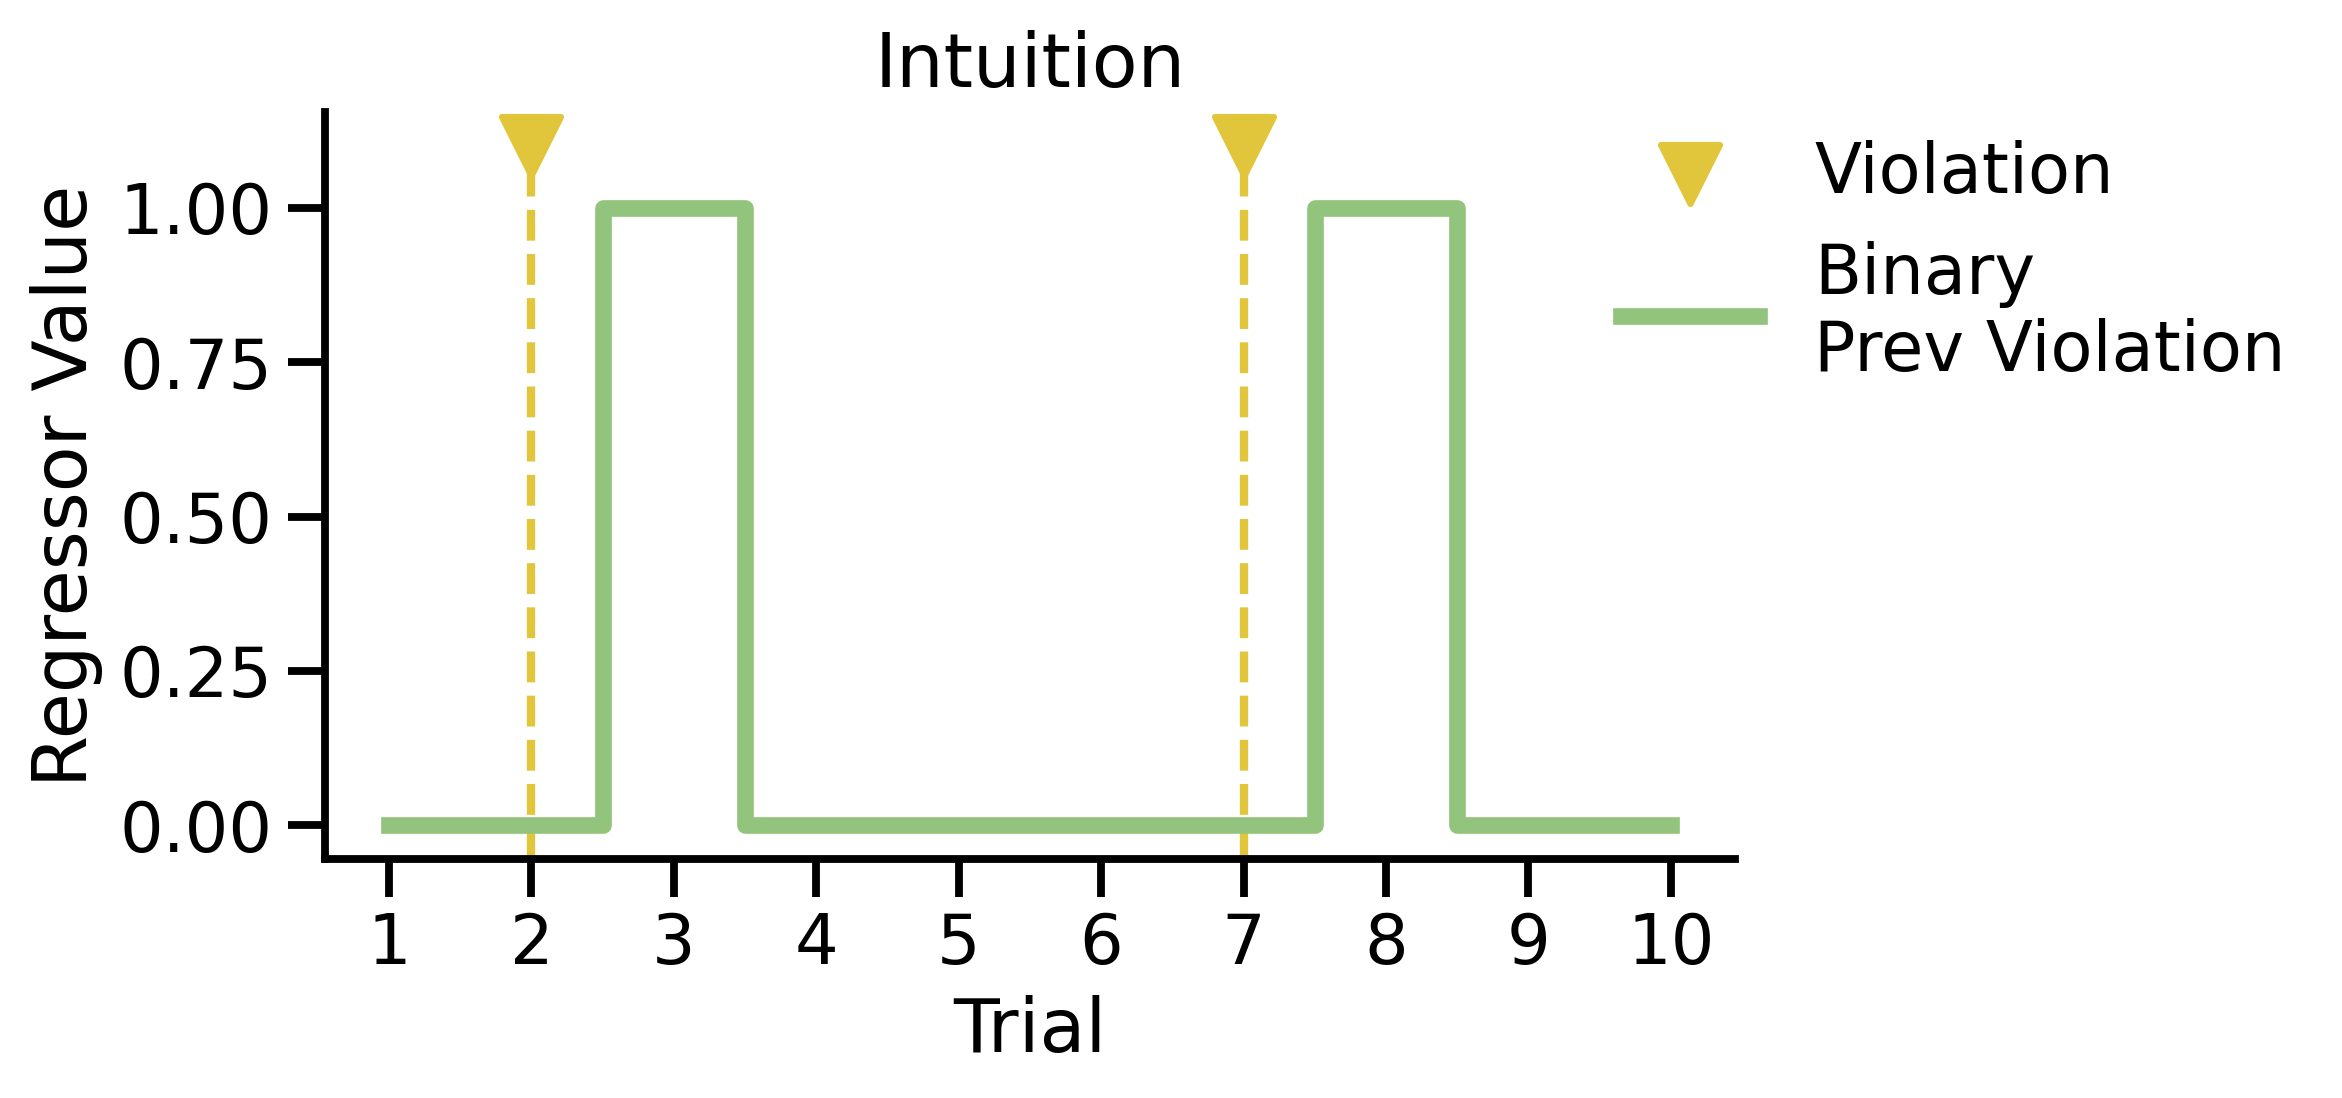

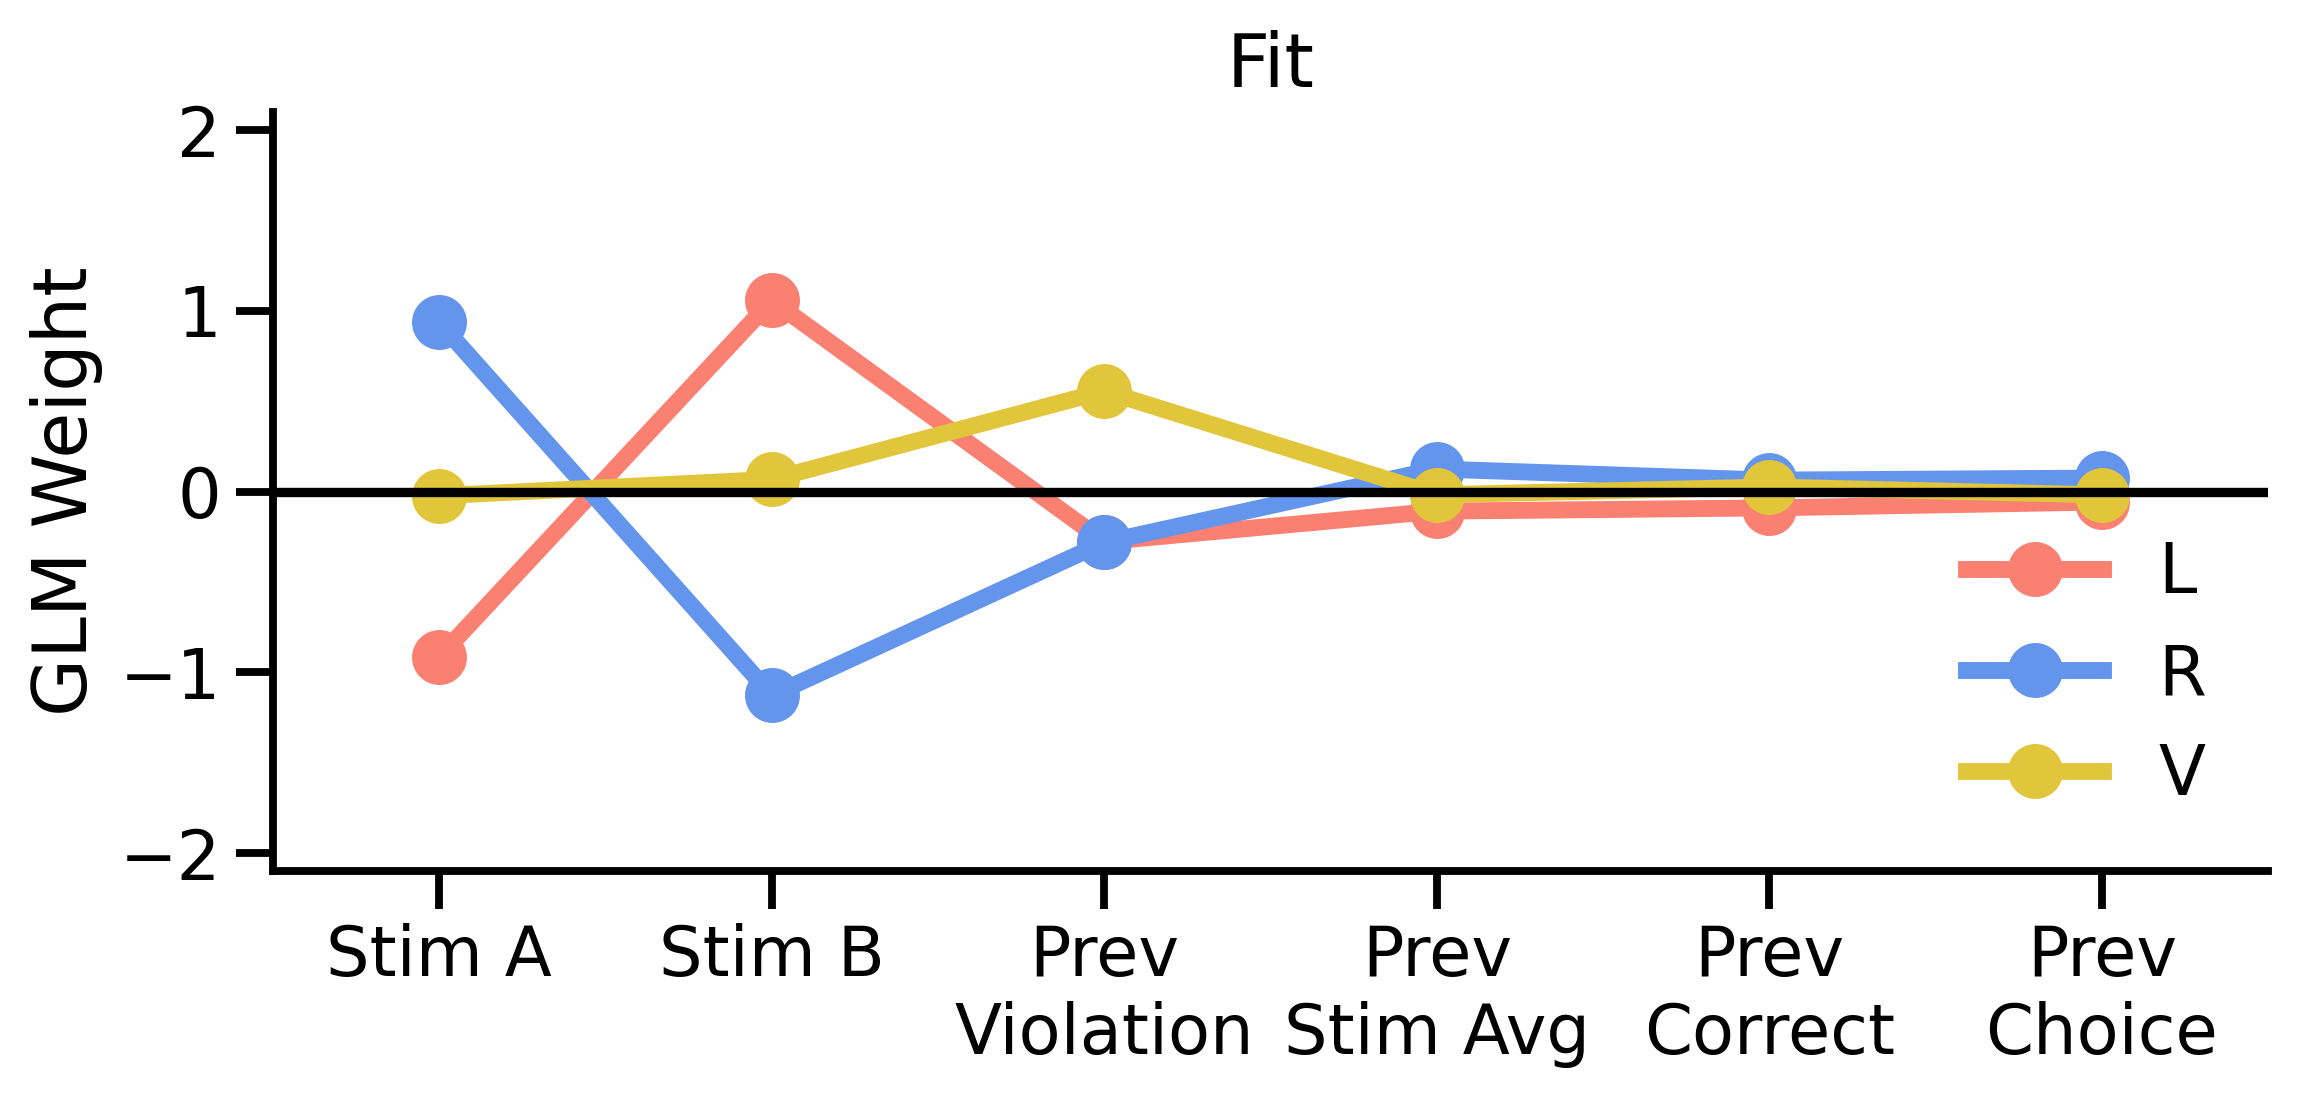

In [4]:
violations = INTUITION.query("violation == 1")
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    violations["trial"],
    violations["violation"] + 0.1,
    color=VIOLATION_COLOR,
    marker="v",
    label="Violation",
    s=200,
)
for trial in violations["trial"]:
    ax.axvline(x=trial, ymax=1.0, color=VIOLATION_COLOR,
               linestyle="--", linewidth=2)
sns.lineplot(
    x=INTUITION["trial"],
    y=INTUITION["prev_violation"],
    drawstyle="steps-mid",
    label="Binary\nPrev Violation",
    ax=ax,
    color=PREV_VIOLATION_COLOR,
    linewidth=4,
)
ax.legend(bbox_to_anchor=(0.90, 1), borderaxespad=0.0, frameon=False)
ax.set(ylabel="Regressor Value", xlabel="Trial", title="Intuition")
ax.set_xticks(np.arange(1, 11))
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "fig03b_prev_violation_intuition")

raw_weights = unpack_weights(best_fits(load_model_summary(RAW_FIT))).query(
    "feature != 'bias'"
)
feature_order = [
    "s_a",
    "s_b",
    "prev_violation",
    "prev_stim_avg",
    "prev_correct",
    "prev_choice",
]
raw_weights["feature"] = pd.Categorical(
    raw_weights["feature"], categories=feature_order, ordered=True
)
fig, ax = plt.subplots(figsize=(8, 4))
sns.pointplot(
    data=raw_weights,
    x="feature",
    y="weight",
    hue="weight_class",
    palette=MULTI_CHOICE_PALETTE,
    errorbar="se",
    ax=ax,
)
ax.axhline(0, color="black")
ax.legend(loc="lower right", frameon=False)
ax.set_xticks(range(len(feature_order)))
ax.set_xticklabels(
    [
        "Stim A",
        "Stim B",
        "Prev\nViolation",
        "Prev\nStim Avg",
        "Prev\nCorrect",
        "Prev\nChoice",
    ]
)
ax.set(xlabel="", ylabel="GLM Weight", title="Fit",
       ylim=(WEIGHT_YMIN, WEIGHT_YMAX))
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "fig03b_prev_violation_weights")

## Panel C — Filtered previous violation intuition and weights

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig03c_filtered_weights.png')

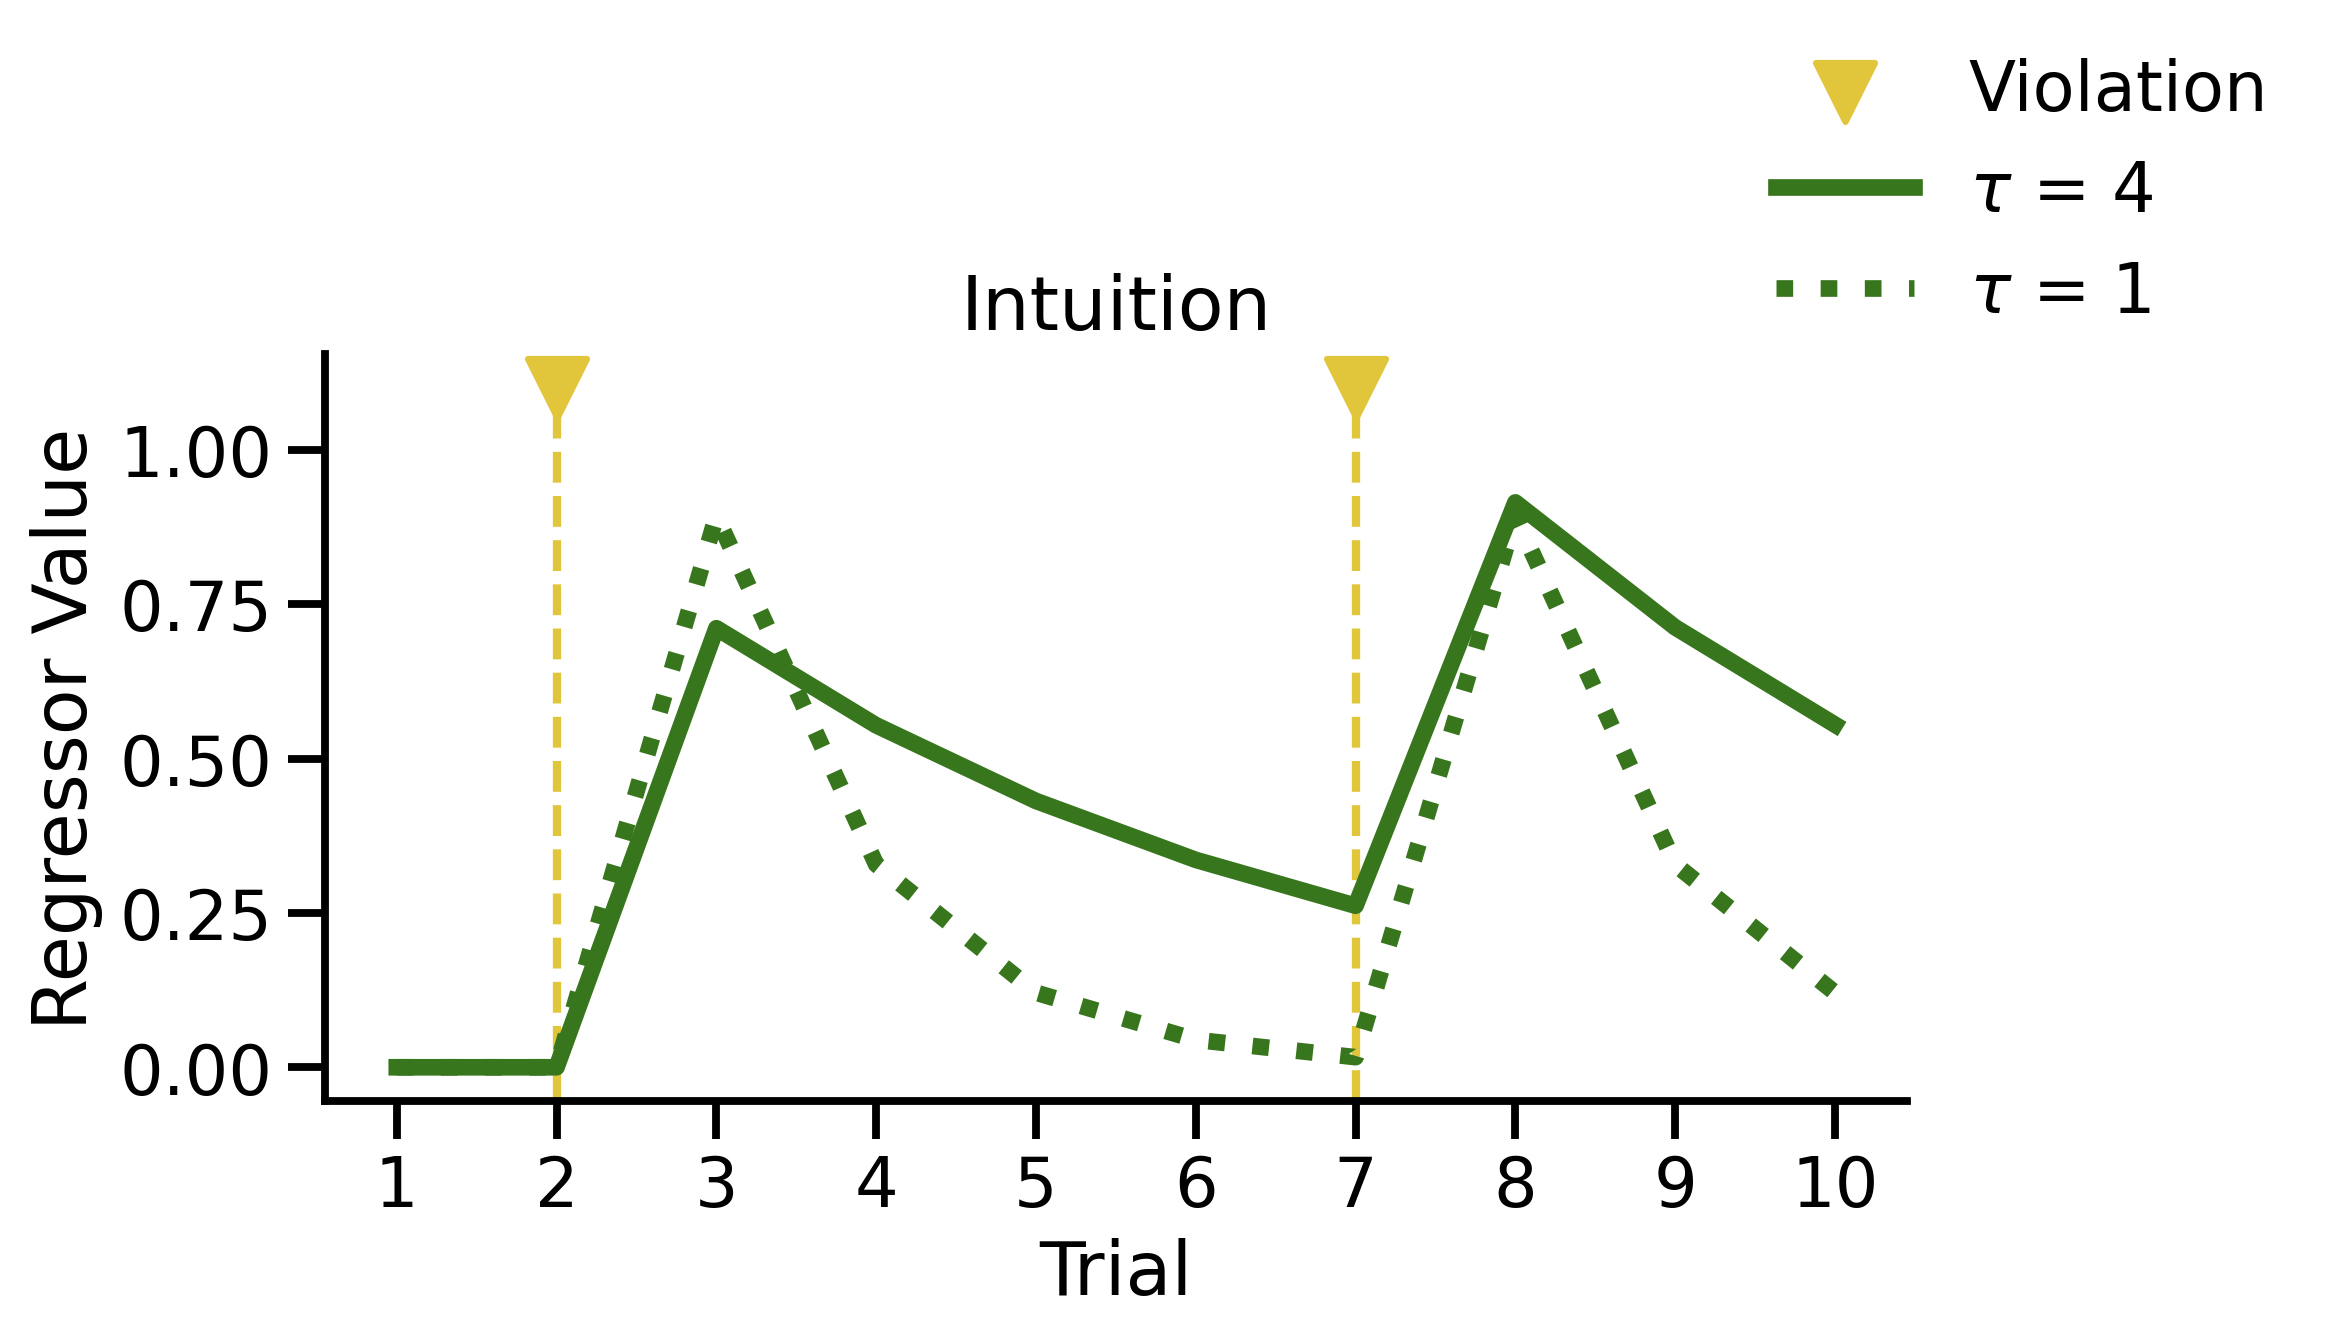

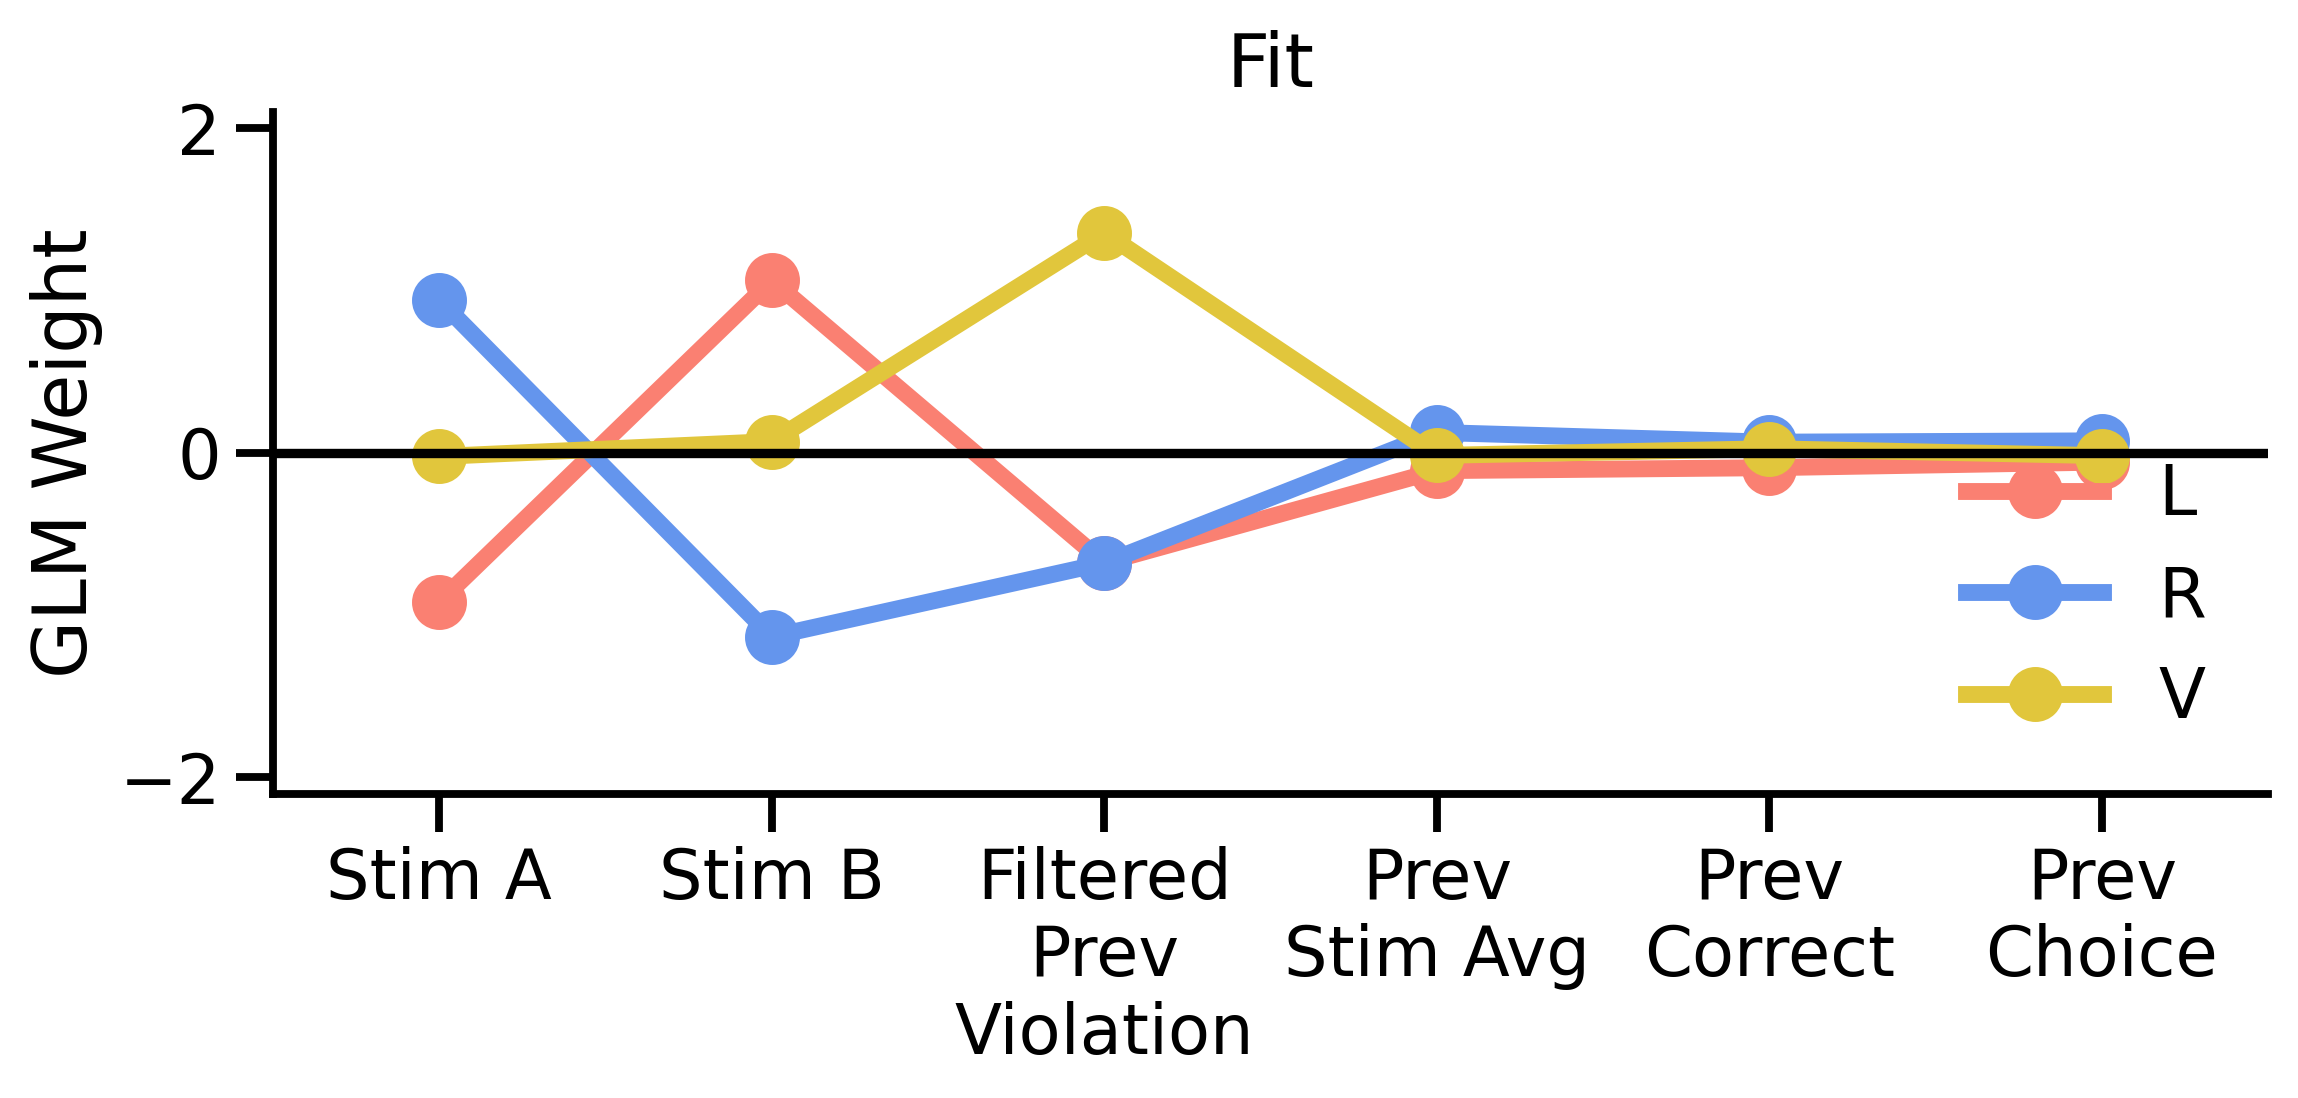

In [5]:
filtered_demo = INTUITION.copy()
for tau, column in ((4, "prev_violation_exp_tau4"), (1, "prev_violation_exp_tau1")):
    kernel = exponential_kernel(tau)
    convolved = np.convolve(filtered_demo["prev_violation"], kernel, mode="full")[
        : len(filtered_demo)
    ]
    filtered_demo[column] = convolved / (convolved.max() + 0.12)

violations = filtered_demo.query("violation == 1")
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    violations["trial"],
    violations["violation"] + 0.1,
    color=VIOLATION_COLOR,
    marker="v",
    label="Violation",
    s=200,
)
for trial in violations["trial"]:
    ax.axvline(x=trial, ymax=1.0, color=VIOLATION_COLOR,
               linestyle="--", linewidth=2)
sns.lineplot(
    x=filtered_demo["trial"],
    y=filtered_demo["prev_violation_exp_tau4"],
    ax=ax,
    color=PREV_VIOLATION_FILTER_COLOR,
    linewidth=4,
    label=r"$\tau$ = 4",
)
sns.lineplot(
    x=filtered_demo["trial"],
    y=filtered_demo["prev_violation_exp_tau1"],
    ax=ax,
    color=PREV_VIOLATION_FILTER_COLOR,
    linewidth=4,
    linestyle=":",
    label=r"$\tau$ = 1",
)
ax.legend(bbox_to_anchor=(0.9, 1), borderaxespad=0.0, frameon=False)
ax.set(ylabel="Regressor Value", xlabel="Trial", title="Intuition")
ax.set_xticks(np.arange(1, 11))
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "fig03c_filtered_intuition")

filtered_weights = unpack_weights(best_fits(load_model_summary(FILTERED_FIT))).query(
    "feature != 'bias'"
)
filtered_feature_order = [
    "s_a",
    "s_b",
    "filt_prev_violation",
    "prev_stim_avg",
    "prev_correct",
    "prev_choice",
]
filtered_weights["feature"] = pd.Categorical(
    filtered_weights["feature"], categories=filtered_feature_order, ordered=True
)
fig, ax = plt.subplots(figsize=(8, 4))
sns.pointplot(
    data=filtered_weights,
    x="feature",
    y="weight",
    hue="weight_class",
    palette=MULTI_CHOICE_PALETTE,
    errorbar=None,
    ax=ax,
)
ax.axhline(0, color="black")
ax.legend(loc="lower right", frameon=False)
ax.set_xticks(range(len(filtered_feature_order)))
ax.set_xticklabels(
    [
        "Stim A",
        "Stim B",
        "Filtered\nPrev\nViolation",
        "Prev\nStim Avg",
        "Prev\nCorrect",
        "Prev\nChoice",
    ]
)
ax.set(xlabel="", ylabel="GLM Weight", title="Fit",
       ylim=(WEIGHT_YMIN, WEIGHT_YMAX))
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "fig03c_filtered_weights")

## Panel D — Exponential time-constant sweep

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig03d_tau_heatmap.png')

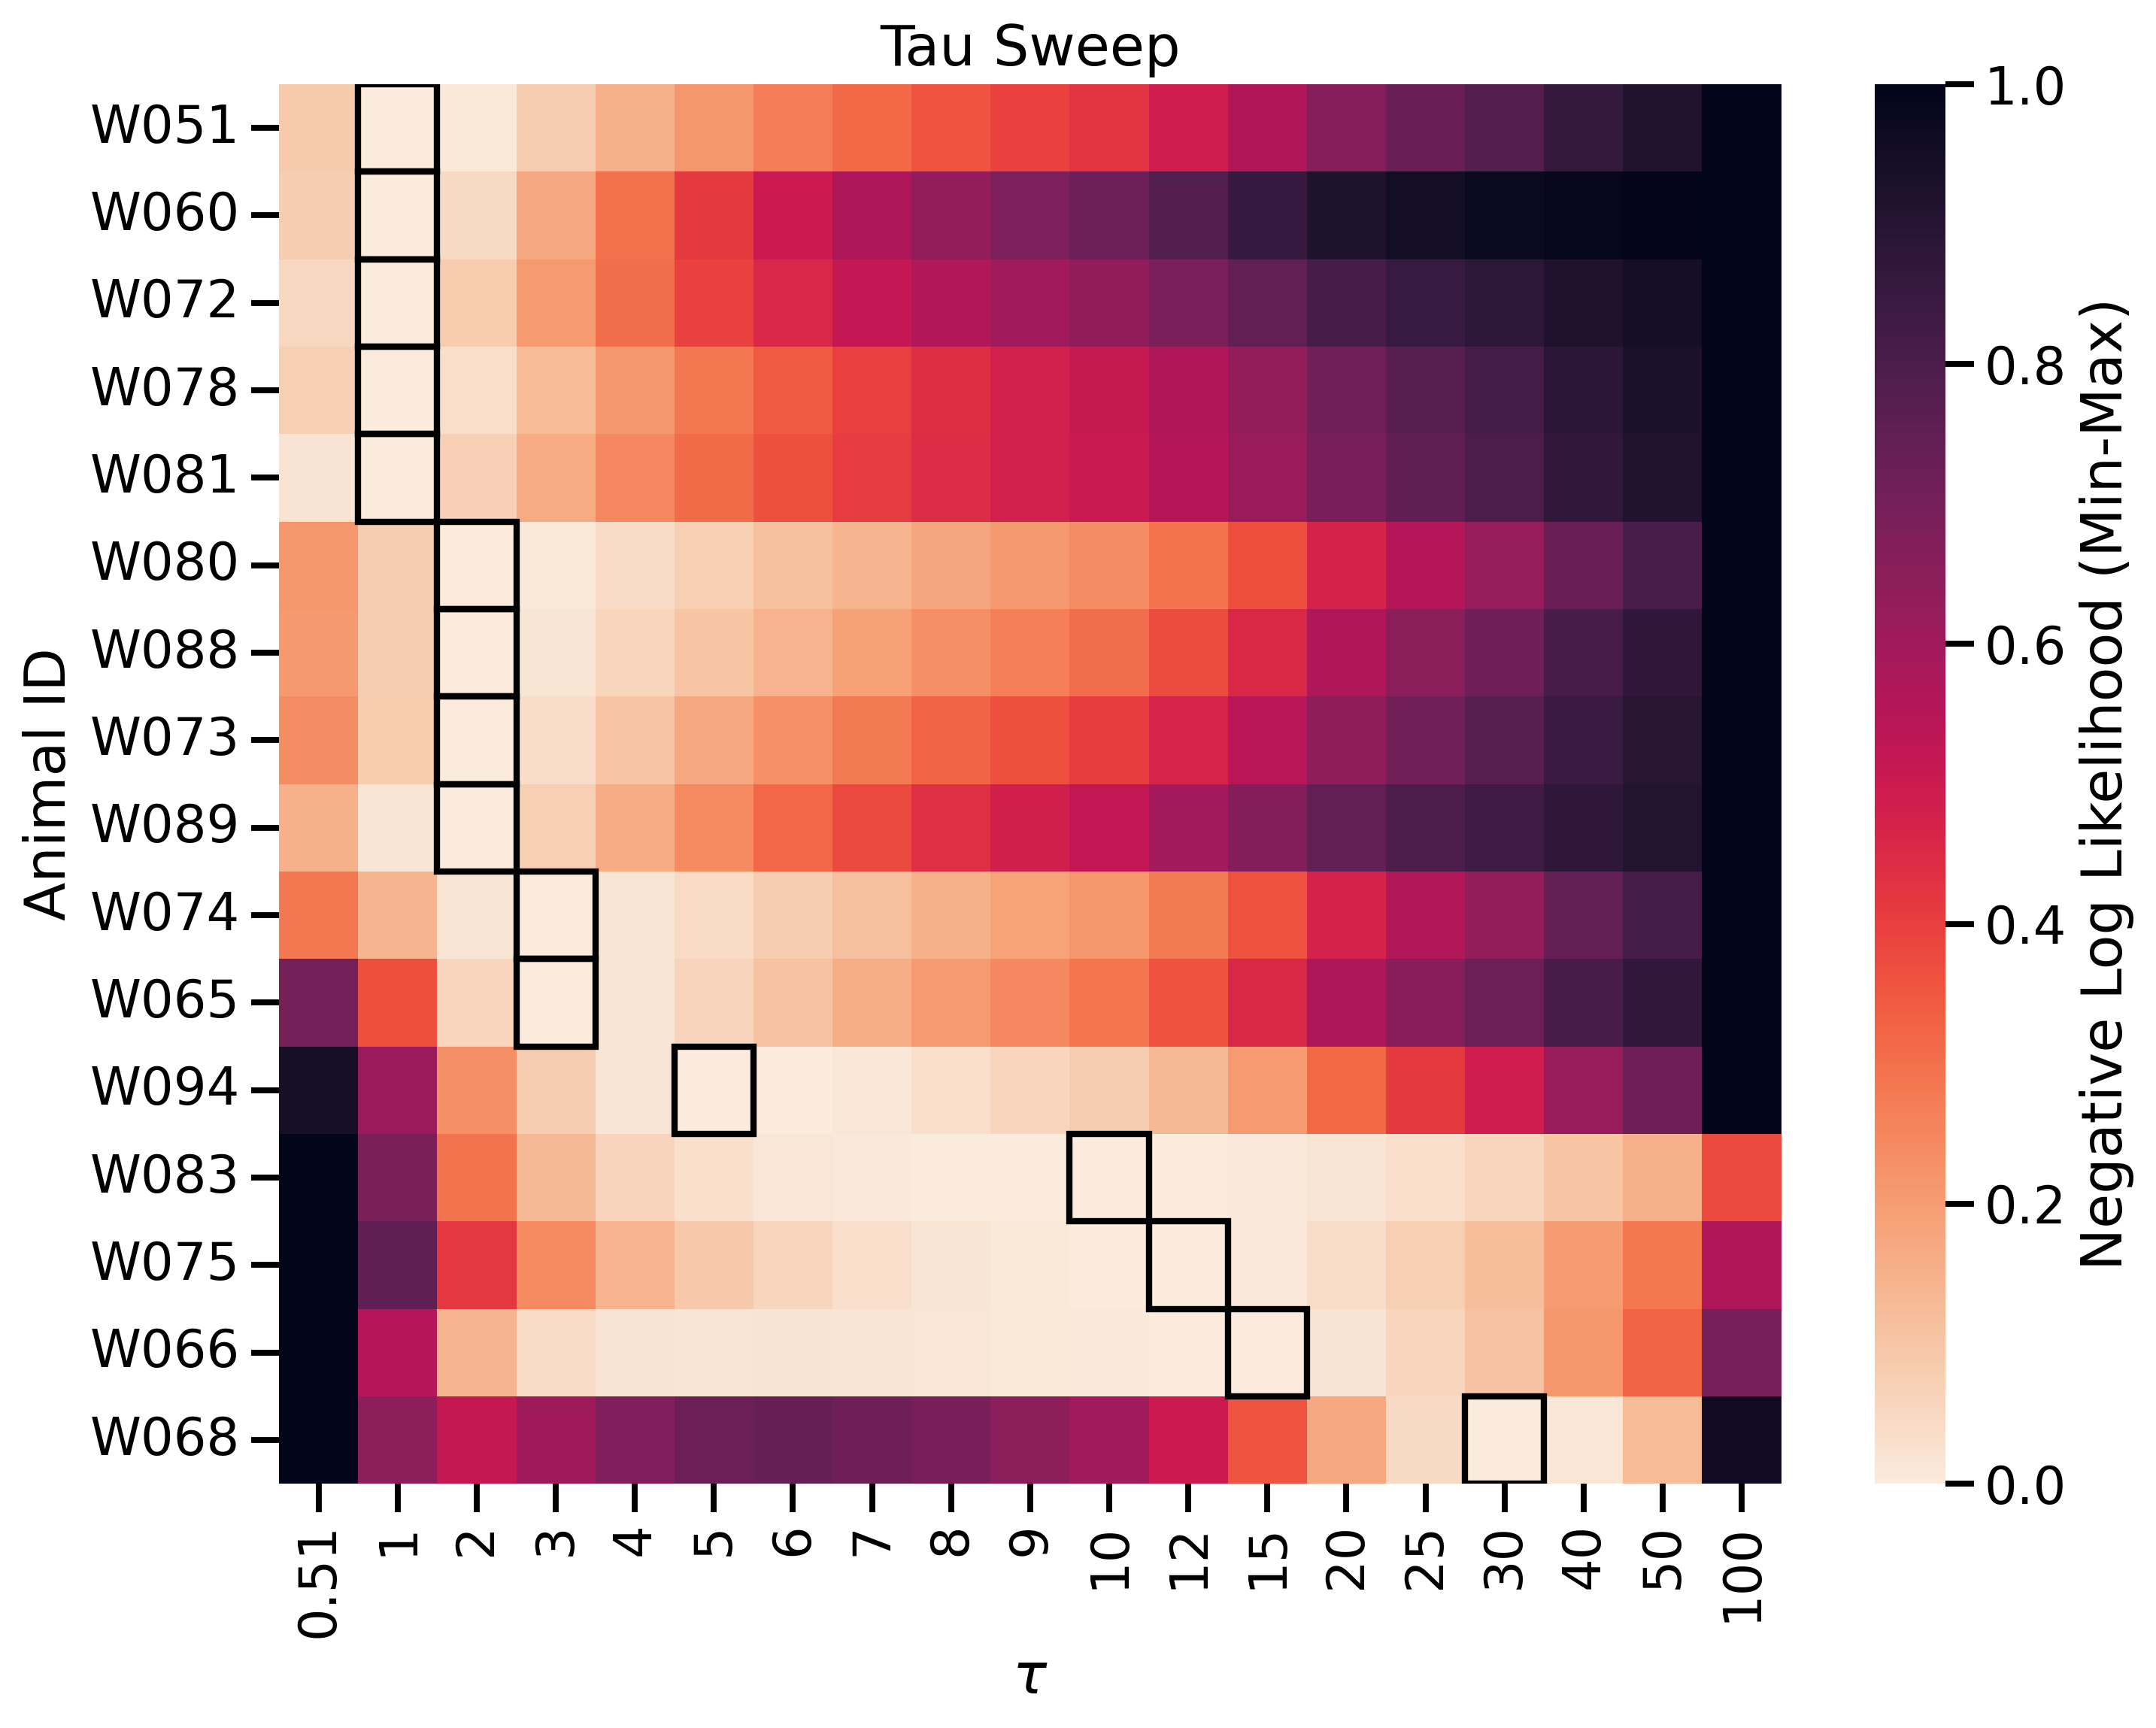

In [6]:
tau_fits = load_model_summary(TAU_SWEEP)
best_tau = best_fits(tau_fits, groups=("animal_id",))[["animal_id", "tau"]].rename(
    columns={"tau": "best_fit_tau"}
)
taus_df = best_fits(tau_fits, groups=("animal_id", "tau"))[
    ["animal_id", "tau", "nll"]
].copy()
taus_df["nll_minmax"] = taus_df.groupby("animal_id", observed=True)["nll"].transform(
    lambda values: (values - values.min()) / (values.max() - values.min())
)
taus_df = taus_df.merge(best_tau, on="animal_id", how="left")
ordered_animals = (
    best_tau.sort_values("best_fit_tau")["animal_id"].tolist()
)
pivot = (
    taus_df.pivot(index="animal_id", columns="tau", values="nll_minmax")
    .reindex(index=ordered_animals)
)

fig, ax = plt.subplots(figsize=(10, 8))
cmap = sns.color_palette("rocket_r", as_cmap=True)
sns.heatmap(
    pivot,
    ax=ax,
    cmap=cmap,
    cbar_kws={"label": "Negative Log Likelihood (Min-Max)"},
)
for animal in pivot.index:
    best = best_tau.loc[best_tau["animal_id"]
                        == animal, "best_fit_tau"].iloc[0]
    col = pivot.columns.get_loc(best)
    row = pivot.index.get_loc(animal)
    ax.add_patch(
        patches.Rectangle((col, row), 1, 1, fill=False, edgecolor="k", lw=2)
    )
ax.set_title("Tau Sweep")
ax.set_xlabel(r"$\tau$")
ax.set_ylabel("Animal ID")
ax.set_xticklabels(
    [f"{value:.0f}" if value != 0.51 else f"{value:.2f}" for value in pivot.columns],
    rotation=90,
    ha="center",
)
fig.tight_layout()
save_figure(fig, "fig03d_tau_heatmap")

## Panel E — Example animal τ profile

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig03e_example_tau.png')

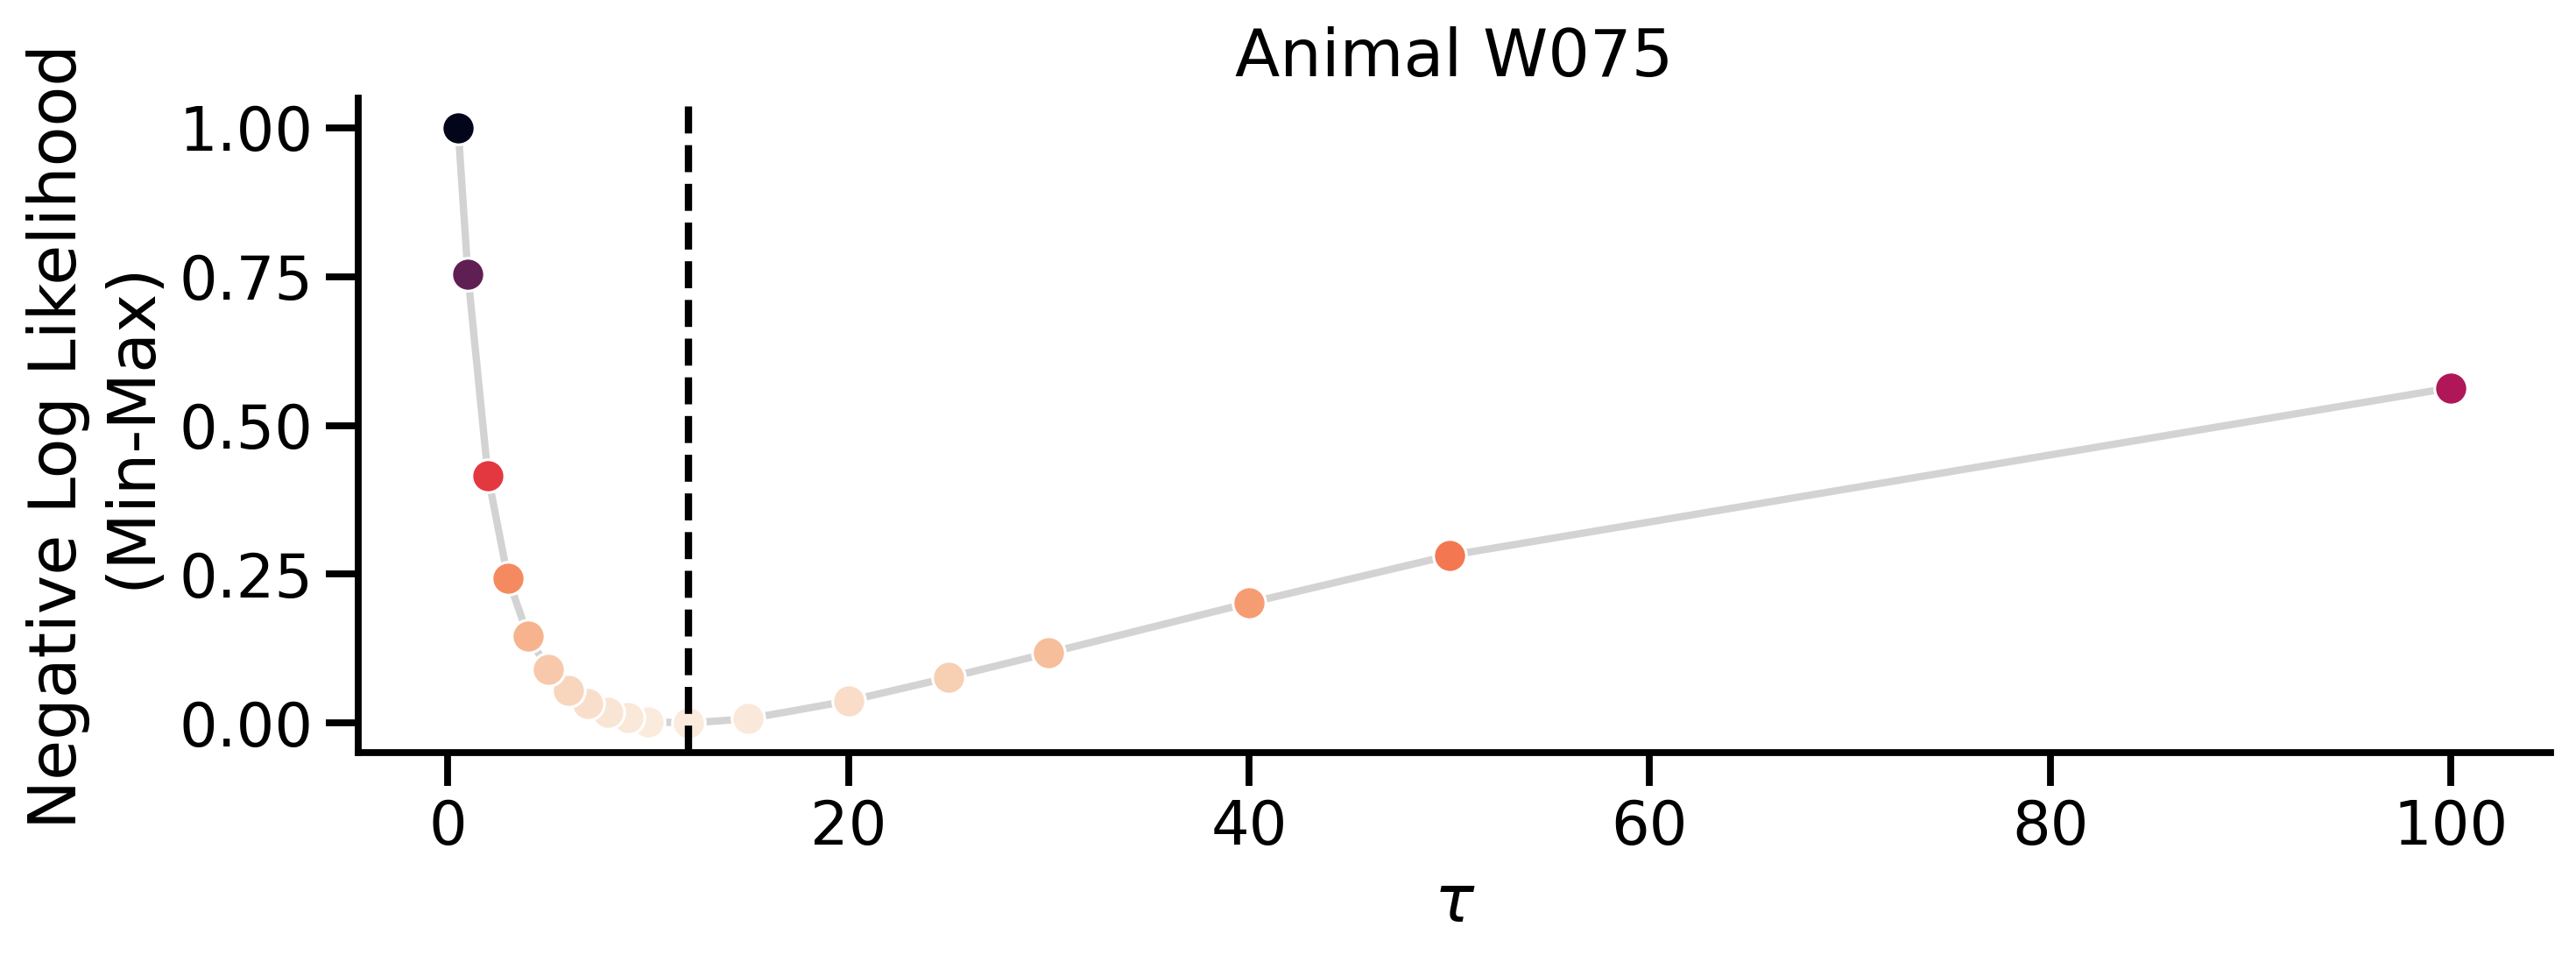

In [7]:
example = taus_df.query("animal_id == @EXAMPLE_ANIMAL")
fig, ax = plt.subplots(figsize=(10, 4))
sns.despine(ax=ax)
sns.lineplot(
    x=example["tau"],
    y=example["nll_minmax"],
    ax=ax,
    linewidth=2,
    color="lightgray",
)
sns.lineplot(
    x=example["tau"],
    y=example["nll_minmax"],
    ax=ax,
    hue=example["nll_minmax"],
    linewidth=3,
    marker="o",
    palette="rocket_r",
    legend=False,
)
ax.axvline(
    x=example["best_fit_tau"].iloc[0],
    color="k",
    linestyle="--",
    linewidth=2,
)
ax.set(
    title=f"Animal {EXAMPLE_ANIMAL}",
    xlabel=r"$\tau$",
    ylabel="Negative Log Likelihood \n(Min-Max)",
)
fig.tight_layout()
save_figure(fig, "fig03e_example_tau")

## Panel F — History-model comparison

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig03f_model_comparison.png')

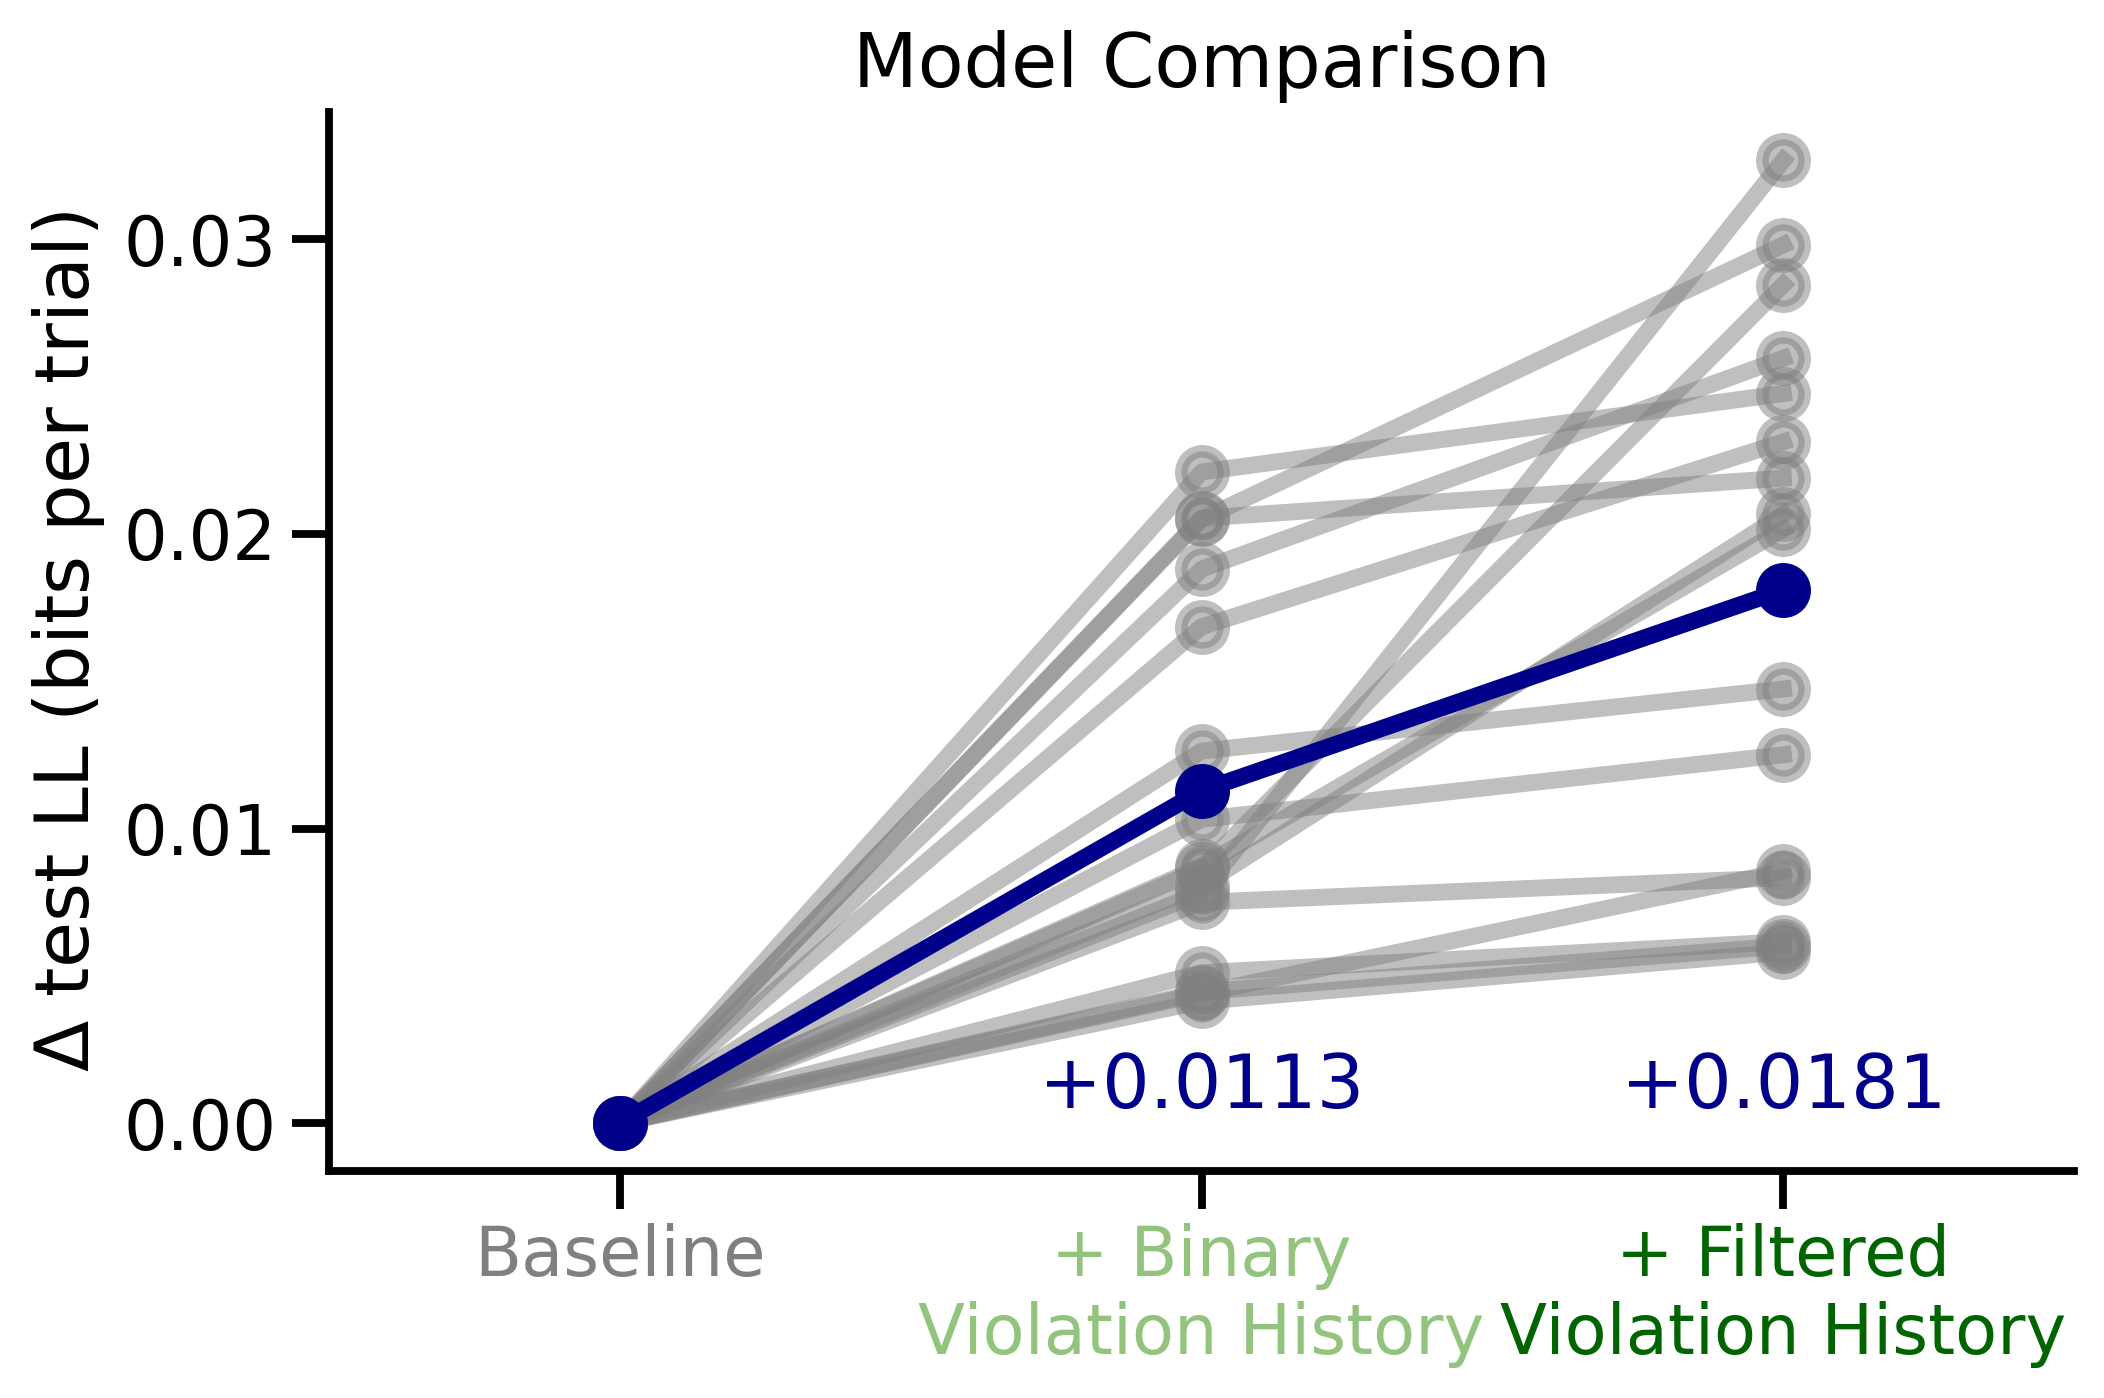

In [8]:
compare_fits = load_model_summary(COMPARE)
compare_null = load_model_summary(COMPARE, kind="null_models")
comparison = bits_per_trial(
    compare_fits, compare_null).query("model_name != 'null'")
order = ["base", "prev_viol_binary", "prev_viol_filtered"]
labels = [
    "Baseline",
    "+ Binary\nViolation History",
    "+ Filtered\nViolation History",
]
tick_colors = ["gray", PREV_VIOLATION_COLOR, "darkgreen"]

fig, ax = plt.subplots(figsize=(7.5, 5))
sns.despine(ax=ax)
sns.pointplot(
    data=comparison,
    x="model_name",
    y="bits_per_trial_relative_to_base",
    hue="animal_id",
    order=order,
    palette=["gray"] * comparison["animal_id"].nunique(),
    alpha=0.5,
    ax=ax,
)
sns.pointplot(
    data=comparison,
    x="model_name",
    y="bits_per_trial_relative_to_base",
    order=order,
    color=MODEL_COMPARE_COLOR,
    errorbar=None,
    ax=ax,
)
for index, model_name in enumerate(order):
    if model_name == order[0]:
        continue
    mean_delta = comparison.loc[
        comparison["model_name"] == model_name, "bits_per_trial_relative_to_base"
    ].mean()
    text = f"+{mean_delta:.4f}" if mean_delta > 0 else f"{mean_delta:.4f}"
    ax.text(index, 0.0005, text, ha="center", color=MODEL_COMPARE_COLOR)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=0)
for tick, color in zip(ax.get_xticklabels(), tick_colors, strict=True):
    tick.set_color(color)
ax.legend().remove()
ax.set(xlabel="", title="Model Comparison",
       ylabel="$\Delta$ test LL (bits per trial)")
fig.tight_layout()
save_figure(fig, "fig03f_model_comparison")

In [9]:
comparison.groupby("model_name").bits_per_trial_relative_to_base.agg(
    ["mean", "std"])

,mean,std
model_name,,
base,0.000000,0.000000
prev_viol_binary,0.011287,0.006384
prev_viol_filtered,0.018103,0.009250


## Base vs Binary

In [10]:
overall_likelihood_ratio(
    compare_fits,
    base_model_name="base",
    new_model_name="prev_viol_binary",
)

/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/src/violations_glm/summaries.py:105: RuntimeWarning: overflow encountered in scalar power
  overall_ratio = 2**overall_diff_bits
/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/src/violations_glm/summaries.py:108: RuntimeWarning: overflow encountered in scalar power
  if math.isinf(2**overall_diff_bits):


{'overall_ratio': inf, 'log10_overall_ratio': np.float64(1256.2841152619944)}

> Pooling across animals, the test data are $10^{1256}$ times more likely under the new model than under the base model.

In [11]:
geometric_mean_likelihood_ratio(
    compare_fits,
    base_model_name="base",
    new_model_name="prev_viol_binary",
)

{'geometric_mean_ratio': 3.2942549248705797e+78,
 'log10_geometric_mean_ratio': np.float64(78.51775720387464)}

> On average, each animal's test data is $1.33 * 10^{78}$ times more likely under the previous violation binary model

## Base vs Filtered

In [12]:
overall_likelihood_ratio(
    compare_fits,
    base_model_name="base",
    new_model_name="prev_viol_filtered",
)

/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/src/violations_glm/summaries.py:105: RuntimeWarning: overflow encountered in scalar power
  overall_ratio = 2**overall_diff_bits
/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/src/violations_glm/summaries.py:108: RuntimeWarning: overflow encountered in scalar power
  if math.isinf(2**overall_diff_bits):


{'overall_ratio': inf, 'log10_overall_ratio': np.float64(2184.3332043946034)}

> Pooling across animals, the test data are $10^{2184}$ times more likely under the new model than under the base model.

In [13]:
geometric_mean_likelihood_ratio(
    compare_fits,
    base_model_name="base",
    new_model_name="prev_viol_filtered",
)

{'geometric_mean_ratio': 3.3176095664555833e+136,
 'log10_geometric_mean_ratio': np.float64(136.5208252746627)}

> On average, each animal's test data is $3.0 * 10^{136}$ times more likely under the previous violation filtered model